# Data Science Fundamentals Assessment
Run cells in order. The retail data and statistical examples are synthetic or illustrative. No predictive model is trained; classification and regression metrics below use fixed example predictions.

In [1]:
from pathlib import Path
import sys, json, runpy
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, seaborn as sns
import scipy, sklearn
from scipy import stats
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT/'data/synthetic_sales.csv').exists(), 'Run from the project root or notebooks/'
OUT=ROOT/'outputs'; FIG=OUT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
print('Python',sys.version.split()[0], 'pandas',pd.__version__,'numpy',np.__version__,'scipy',scipy.__version__,'matplotlib',matplotlib.__version__,'seaborn',sns.__version__,'sklearn',sklearn.__version__)
sns.set_theme(style='whitegrid')

Python 3.13.16 pandas 2.2.3 numpy 2.3.5 scipy 1.17.1 matplotlib 3.10.9 seaborn 0.13.2 sklearn 1.6.1


## 1. Python fundamentals
The script demonstrates variables, types, conversions, operators, strings, collections, control flow, functions, comprehensions, exceptions, files, imports and assertions. Output and assertions are executed below.

In [2]:
runpy.run_path(str(ROOT/'scripts/fundamentals_examples.py'))

Types: int float str bool NoneType
Conversion: 12 2.5 42 True
Operators: 9 5 14 3.5 3 1 49
Comparisons/logical/membership: True True True True True False True
String: data science D Data Data Lab
Collections: ['pen', 'book', 'ruler'] (2, 3) 2 Asha
Conditional: medium
Loops: [0, 1, 3, 4] 3
Function/comprehension: 37.5 [0, 4, 16] 4.0
Exceptions: 8 invalid integer
File: hello
All assertions passed


{'__name__': '<run_path>',
 '__doc__': 'Executable Python fundamentals examples and assertions; run from any directory.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/home/user/data-science-fundamentals-assessment/scripts/fundamentals_examples.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__':

## 2. Small illustrative statistics dataset
Use x = [2, 4, 4, 4, 5, 5, 7, 9]. Quartiles use the Pandas default linear interpolation; sample variance uses ddof=1, population variance ddof=0. Inference here is purely a numerical demonstration, not evidence about an actual population.

In [3]:
x=np.array([2,4,4,4,5,5,7,9],dtype=float); ser=pd.Series(x)
q1,q3=ser.quantile([.25,.75]); t=stats.ttest_1samp(x,popmean=4)
ci=stats.t.interval(.95,df=len(x)-1,loc=x.mean(),scale=stats.sem(x))
obs=np.array([[8,2],[4,6]]); chi=stats.chi2_contingency(obs,correction=False)
print('sum, mean, median, mode:', x.sum(), x.mean(), np.median(x), ser.mode().tolist())
print('min, max, range, Q1, Q3, IQR:',x.min(),x.max(),np.ptp(x),q1,q3,q3-q1)
print('sum squared deviations, population/sample variance, population/sample SD:',sum((x-x.mean())**2),x.var(ddof=0),x.var(ddof=1),x.std(ddof=0),x.std(ddof=1))
print('sample skewness (adjusted Fisher-Pearson):',ser.skew()); print('frequency:',ser.value_counts().sort_index().to_dict())
print('SE:',stats.sem(x),'95% t CI:',ci,'one-sample t against 4:',t)
print('chi square, p, df, expected:',chi.statistic,chi.pvalue,chi.dof,chi.expected_freq)
print('binomial P(X=2), n=4 p=.5:', stats.binom.pmf(2,4,.5))
print('normal P(Z<=1.96):',stats.norm.cdf(1.96))
print('covariance and correlation x and 2x:',np.cov(x,2*x,ddof=1)[0,1],np.corrcoef(x,2*x)[0,1])
assert np.isclose(x.mean(),5) and np.isclose(x.var(),4) and np.isclose(x.var(ddof=1),32/7)

sum, mean, median, mode: 40.0 5.0 4.5 [4.0]
min, max, range, Q1, Q3, IQR: 2.0 9.0 7.0 4.0 5.5 1.5
sum squared deviations, population/sample variance, population/sample SD: 32.0 4.0 4.571428571428571 2.0 2.138089935299395
sample skewness (adjusted Fisher-Pearson): 0.8184875533567997
frequency: {2.0: 1, 4.0: 3, 5.0: 2, 7.0: 1, 9.0: 1}
SE: 0.7559289460184544 95% t CI: (np.float64(3.21251208176379), np.float64(6.787487918236209)) one-sample t against 4: TtestResult(statistic=np.float64(1.3228756555322954), pvalue=np.float64(0.22745281805976297), df=np.int64(7))
chi square, p, df, expected: 3.333333333333333 0.06788915486182878 1 [[6. 4.]
 [6. 4.]]
binomial P(X=2), n=4 p=.5: 0.375
normal P(Z<=1.96): 0.9750021048517795
covariance and correlation x and 2x: 9.142857142857142 0.9999999999999998


## 3. Load and validate the practical dataset
The generated CSV has deliberate problems. Inspect raw records before changing them. Normalize category text before grouping; remove exact duplicates before imputation. Missing units use the category median; this is an assumption, not recovery of the true value.

In [4]:
raw=pd.read_csv(ROOT/'data/synthetic_sales.csv')
print('Raw shape:',raw.shape); print('Columns:',raw.columns.tolist()); raw.info(); display(raw.head()); display(raw.describe(include='all'))
print('Raw missing counts:',raw.isna().sum().to_dict()); print('Raw duplicate rows:',raw.duplicated().sum()); print('Raw categories:',raw.category.unique())
clean=raw.drop_duplicates().copy(); clean['category']=clean['category'].str.strip().str.title(); clean['date']=pd.to_datetime(clean['date'],errors='raise')
assert set(clean.category).issubset({'Books','Electronics','Home'})
assert clean.unit_price_usd.gt(0).all() and clean.units.dropna().between(1,6).all()
clean['units']=clean['units'].fillna(clean.groupby('category')['units'].transform('median')).round().astype(int)
clean['revenue_usd']=(clean.units*clean.unit_price_usd).round(2)
assert clean.sale_id.is_unique and not clean.isna().any().any()
lookup=pd.DataFrame({'category':['Books','Electronics','Home'],'department':['Media','Technology','Household']})
clean=clean.merge(lookup,on='category',how='left',validate='many_to_one')
assert clean.department.notna().all() and len(clean)==120
clean.to_csv(OUT/'cleaned_sales.csv',index=False)
print('Clean shape:',clean.shape); print('Filtered and sorted rows:'); display(clean.loc[clean.revenue_usd>=200,['sale_id','category','revenue_usd']].sort_values('revenue_usd',ascending=False).head())
category=clean.groupby('category',as_index=False).agg(transactions=('sale_id','size'),units=('units','sum'),revenue_usd=('revenue_usd','sum')).sort_values('revenue_usd',ascending=False)
monthly=clean.assign(month=clean.date.dt.to_period('M').dt.to_timestamp()).groupby('month',as_index=False).revenue_usd.sum()
print('Category summary:'); display(category); print('Monthly summary:'); display(monthly)
print('Revenue description:'); display(clean.revenue_usd.describe()); print('Numeric Pearson correlations:'); display(clean[['units','unit_price_usd','revenue_usd']].corr())
q1r,q3r=clean.revenue_usd.quantile([.25,.75]); iqr=q3r-q1r; outliers=clean[(clean.revenue_usd<q1r-1.5*iqr)|(clean.revenue_usd>q3r+1.5*iqr)]
print('Global IQR fences:',q1r-1.5*iqr,q3r+1.5*iqr,'flag count:',len(outliers))

Raw shape: (122, 5)
Columns: ['sale_id', 'date', 'category', 'units', 'unit_price_usd']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sale_id         122 non-null    object 
 1   date            122 non-null    object 
 2   category        122 non-null    object 
 3   units           119 non-null    float64
 4   unit_price_usd  122 non-null    int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 4.9+ KB


,sale_id,date,category,units,unit_price_usd
0,S001,2025-01-01,Books,6.0,20
1,S002,2025-01-02,Electronics,4.0,65
2,S003,2025-01-03,Electronics,6.0,65
3,S004,2025-01-04,Electronics,6.0,65
4,S005,2025-01-05,Electronics,5.0,65


,sale_id,date,category,units,unit_price_usd
count,122,122,122,119.000000,122.000000
unique,120,120,4,NaN,NaN
top,S021,2025-01-21,Electronics,NaN,NaN
freq,2,2,47,NaN,NaN
mean,NaN,NaN,NaN,3.378151,41.762295
std,NaN,NaN,NaN,1.746627,19.390742
min,NaN,NaN,NaN,1.000000,20.000000
25%,NaN,NaN,NaN,2.000000,20.000000
50%,NaN,NaN,NaN,3.000000,35.000000
75%,NaN,NaN,NaN,5.000000,65.000000


Raw missing counts: {'sale_id': 0, 'date': 0, 'category': 0, 'units': 3, 'unit_price_usd': 0}
Raw duplicate rows: 2
Raw categories: ['Books' 'Electronics' 'Home' ' books ']
Clean shape: (120, 7)
Filtered and sorted rows:


,sale_id,category,revenue_usd
2,S003,Electronics,390
3,S004,Electronics,390
21,S022,Electronics,390
27,S028,Electronics,390
36,S037,Electronics,390


...

Revenue description:


count    120.000000
mean     137.375000
std       96.488695
min       20.000000
25%       65.000000
50%      120.000000
75%      195.000000
max      390.000000
Name: revenue_usd, dtype: float64

Numeric Pearson correlations:


,units,unit_price_usd,revenue_usd
units,1.000000,-0.107070,0.675806
unit_price_usd,-0.107070,1.000000,0.576481
revenue_usd,0.675806,0.576481,1.000000


Global IQR fences: -130.0 390.0 flag count: 0


## 4. Visualizations
Bar: category totals; line: monthly totals; histogram and box plot: revenue distributions; scatter: units and revenue; heatmap: Pearson correlations. Revenue is constructed from units and price, so its correlations are partly mechanical.

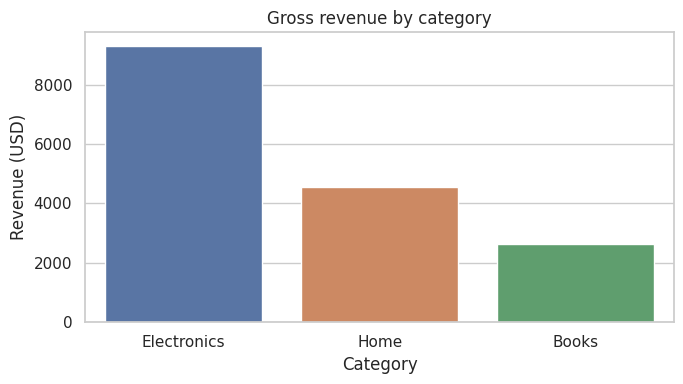

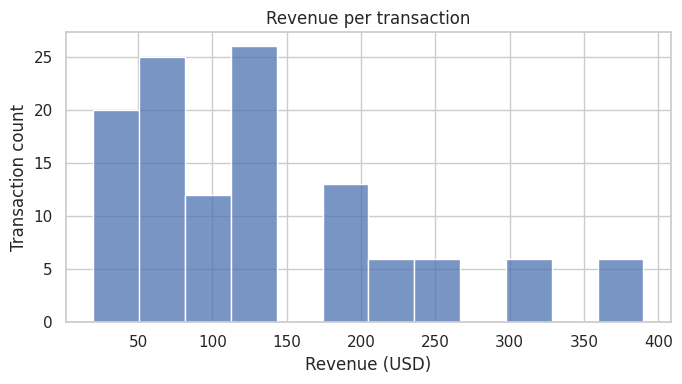

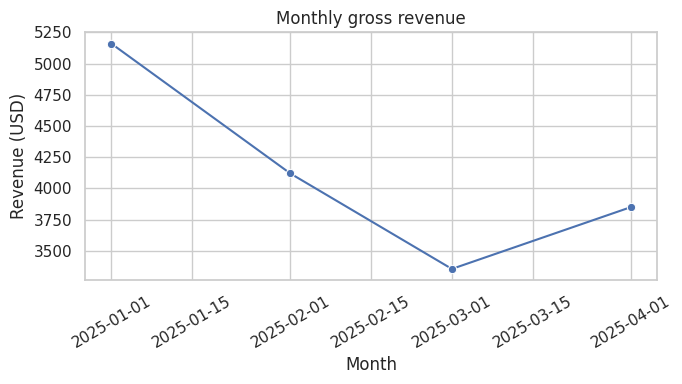

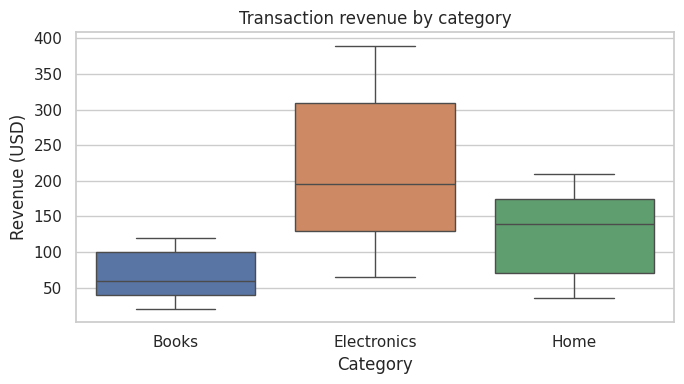

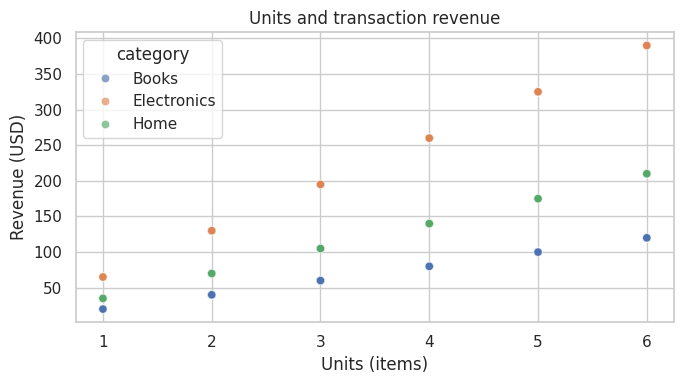

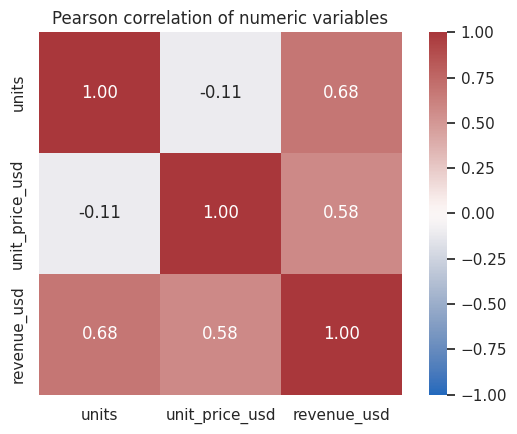

In [5]:
def save(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=150,bbox_inches='tight'); plt.show(); plt.close()
plt.figure(figsize=(7,4)); sns.barplot(data=category,x='category',y='revenue_usd',hue='category',legend=False); plt.title('Gross revenue by category'); plt.xlabel('Category'); plt.ylabel('Revenue (USD)'); save('01_bar.png')
plt.figure(figsize=(7,4)); sns.histplot(clean.revenue_usd,bins=12); plt.title('Revenue per transaction'); plt.xlabel('Revenue (USD)'); plt.ylabel('Transaction count'); save('02_histogram.png')
plt.figure(figsize=(7,4)); sns.lineplot(data=monthly,x='month',y='revenue_usd',marker='o'); plt.title('Monthly gross revenue'); plt.xlabel('Month'); plt.ylabel('Revenue (USD)'); plt.xticks(rotation=30); save('03_line.png')
plt.figure(figsize=(7,4)); sns.boxplot(data=clean,x='category',y='revenue_usd',hue='category',legend=False); plt.title('Transaction revenue by category'); plt.xlabel('Category'); plt.ylabel('Revenue (USD)'); save('04_box.png')
plt.figure(figsize=(7,4)); sns.scatterplot(data=clean,x='units',y='revenue_usd',hue='category',alpha=.65); plt.title('Units and transaction revenue'); plt.xlabel('Units (items)'); plt.ylabel('Revenue (USD)'); save('05_scatter.png')
plt.figure(figsize=(6,4.5)); sns.heatmap(clean[['units','unit_price_usd','revenue_usd']].corr(),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',square=True); plt.title('Pearson correlation of numeric variables'); save('06_heatmap.png')

## 5. Model evaluation examples, not a trained model
Fixed labels and scores illustrate threshold-based classification metrics; the holdout and cross-validation concepts are discussed in the report. Regression metrics are verified from fixed truth/prediction pairs. No performance claim or generalization estimate is made.

In [6]:
y=np.array([1]*10+[0]*10); pred=np.array([1]*8+[0]*2+[1]*3+[0]*7); scores=np.array([.9]*8+[.4]*2+[.8]*3+[.2]*7)
tn,fp,fn,tp=confusion_matrix(y,pred).ravel(); accuracy=accuracy_score(y,pred); precision=precision_score(y,pred); recall=recall_score(y,pred); specificity=tn/(tn+fp); f1=f1_score(y,pred); auc=roc_auc_score(y,scores)
print('Confusion matrix [[TN,FP],[FN,TP]]:',confusion_matrix(y,pred)); print('accuracy precision recall specificity F1 ROC-AUC:',accuracy,precision,recall,specificity,f1,auc)
yr=np.array([3,5,7,9]); pr=np.array([2,5,8,8]); residual=yr-pr
mae=mean_absolute_error(yr,pr); mse=mean_squared_error(yr,pr); rmse=np.sqrt(mse); r2=r2_score(yr,pr)
print('Regression residuals y - yhat:',residual,'MAE MSE RMSE R2:',mae,mse,rmse,r2)
assert (tn,fp,fn,tp)==(7,3,2,8) and np.isclose(mae,.75) and np.isclose(mse,.75)
summary={'raw_shape':list(raw.shape),'raw_duplicates':int(raw.duplicated().sum()),'raw_missing':{k:int(v) for k,v in raw.isna().sum().items()},'clean_shape':list(clean.shape),'revenue_total':float(clean.revenue_usd.sum()),'revenue_mean':float(clean.revenue_usd.mean()),'revenue_median':float(clean.revenue_usd.median()),'categories':category.to_dict(orient='records'),'months':[{'month':v.month.strftime('%Y-%m'),'revenue':float(v.revenue_usd)} for v in monthly.itertuples()],'units_price_corr':float(clean.units.corr(clean.unit_price_usd)),'outlier_fences':[float(q1r-1.5*iqr),float(q3r+1.5*iqr)],'outlier_count':int(len(outliers)),'stats_example':{'q1':float(q1),'q3':float(q3),'skew':float(ser.skew()),'se':float(stats.sem(x)),'ci':[float(i) for i in ci],'t':float(t.statistic),'t_p':float(t.pvalue),'chi2':float(chi.statistic),'chi2_p':float(chi.pvalue)},'classification':{'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),'accuracy':float(accuracy),'precision':float(precision),'recall':float(recall),'specificity':float(specificity),'f1':float(f1),'auc':float(auc)},'regression':{'mae':float(mae),'mse':float(mse),'rmse':float(rmse),'r2':float(r2)},'versions':{'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'seaborn':sns.__version__,'scikit-learn':sklearn.__version__}}
(OUT/'analysis_summary.json').write_text(json.dumps(summary,indent=2)); print('Exported outputs to',OUT)

Confusion matrix [[TN,FP],[FN,TP]]: [[7 3]
 [2 8]]
accuracy precision recall specificity F1 ROC-AUC: 0.75 0.7272727272727273 0.8 0.7 0.7619047619047619 0.94
Regression residuals y - yhat: [ 1  0 -1  1] MAE MSE RMSE R2: 0.75 0.75 0.8660254037844386 0.85
Exported outputs to /home/user/data-science-fundamentals-assessment/outputs
